In [2]:
import pandas as pd

In [3]:
data=pd.read_csv('Patient_medical_cost.csv')

In [ ]:
data=data.drop(columns='patient_id')

x=data.drop(columns='annual_medical_cost')
y=data['annual_medical_cost']

In [38]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)  

from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose  import ColumnTransformer

number_pipeline=Pipeline([
    ('scalar',StandardScaler())
])

catagory_pipeline=Pipeline([
    ('ohe',OneHotEncoder(handle_unknown='ignore',sparse_output=False,drop='first'))
])

preprocessor=ColumnTransformer([
    ('number_pipeline',number_pipeline,number),
    ('catagory_pipeline',catagory_pipeline,['gender','region'])
])


x_train_final= preprocessor.fit_transform(x_train)
x_test_final=preprocessor.transform(x_test)
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train_final,y_train)
print(model.coef_)


[    4.93336622 -1229.19896508  1740.31386116   956.23009513
  -499.23909852    99.92596995    22.10912348   220.36108841
    41.24815726   898.34068572  -579.98989112  -254.67100355
   205.99758848   162.5533468    122.09014217    70.27843246
    35.81976082   720.08077418   452.57860146  1081.50357003]


Text(0.5, 1.0, 'linear_train_score vs linear_test_score')

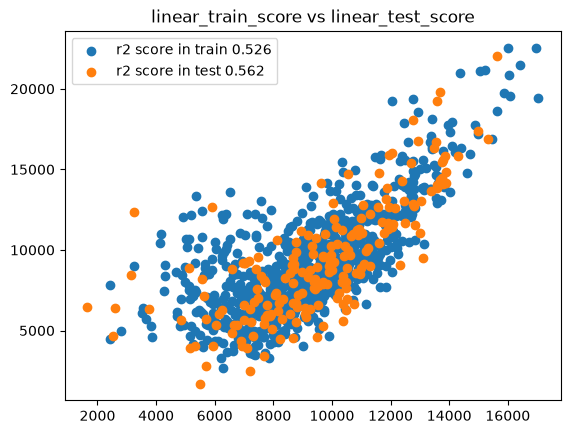

In [51]:
from sklearn.metrics import r2_score
linear_train_score=model.predict(x_train_final)
linear_test_score=model.predict(x_test_final)


r2_linear_train_score=r2_score(y_train,linear_train_score)
r2_linear_test_score=r2_score(y_test,linear_test_score)
import matplotlib.pyplot as plt
plt.scatter(linear_train_score,y_train,label=(f"r2 score in train {r2_linear_train_score:0.3f}"))
plt.scatter(linear_test_score,y_test,label=(f'r2 score in test {r2_linear_test_score:0.3f}'))
plt.legend();plt.title('linear_train_score vs linear_test_score')

In [27]:
number=x_train.describe().select_dtypes(include='number').columns.to_list()

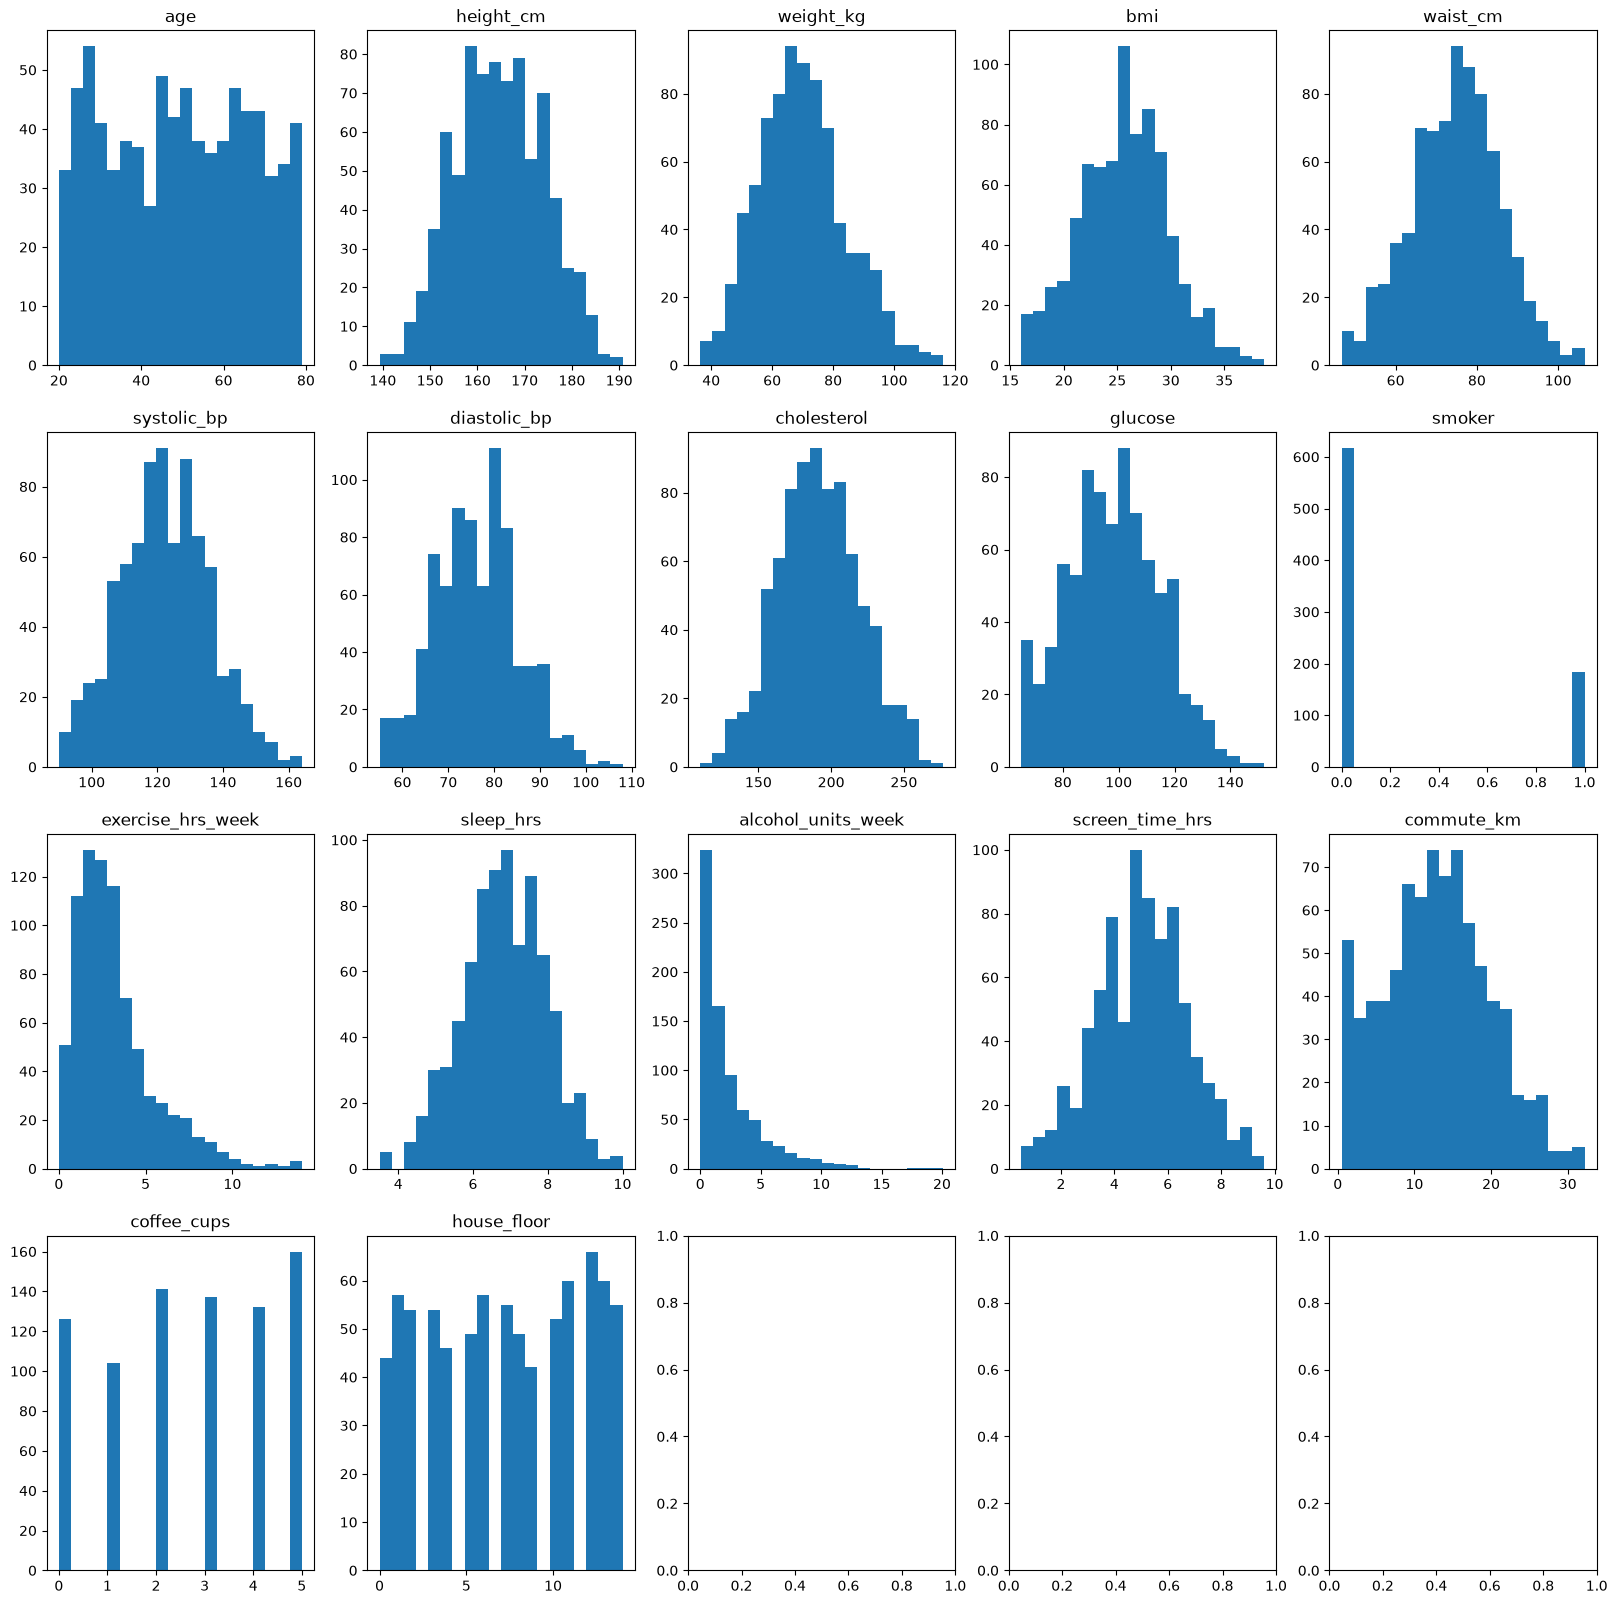

In [39]:
import matplotlib.pyplot as plt
fig,ax= plt.subplots(4,5,figsize=(20,20))
for axes,cols in zip(ax.ravel(),x_train[number]):
    axes.hist(x_train[cols],bins=20)
    axes.set_title(cols)


Polynomial regression 


In [ ]:
from sklearn.preprocessing import PolynomialFeatures

poly=PolynomialFeatures(2)
x_train_poly=poly.fit_transform(x_train_final)
x_test_poly=poly.transform(x_test_final)
poly_linear_model=LinearRegression()
poly_linear_model.fit(x_train_poly,y_train)

poly_linear_train_score=poly_linear_model.predict(x_train_poly)
poly_linear_test_score=poly_linear_model.predict(x_test_poly)

r2_poly_linear_train_score=r2_score(y_train,poly_linear_train_score)
r2_poly_linear_test_score=r2_score(y_test,poly_linear_test_score)



Text(0.5, 1.0, 'POLY_linear_train_score vs POLY_linear_test_score')

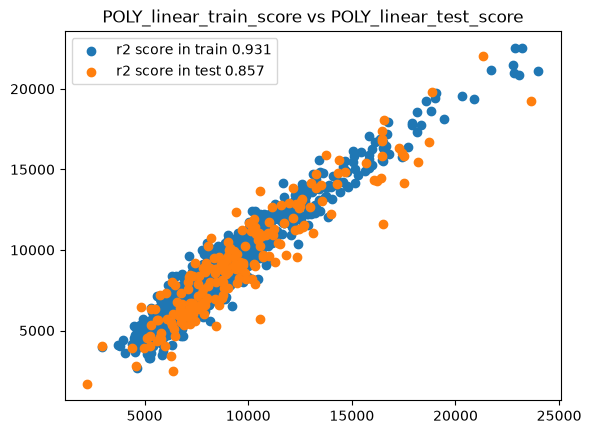

In [58]:
import matplotlib.pyplot as plt
plt.scatter(poly_linear_train_score,y_train,label=(f"r2 score in train {r2_poly_linear_train_score:0.3f}"))
plt.scatter(poly_linear_test_score,y_test,label=(f'r2 score in test {r2_poly_linear_test_score:0.3f}'))
plt.legend();plt.title('POLY_linear_train_score vs POLY_linear_test_score')

RIDGE REGRESSION


In [64]:
from sklearn.linear_model import Ridge

ridge_model=Ridge(alpha=0.01)
ridge_model.fit(x_train_final,y_train)

ridge_train_score=ridge_model.predict(x_train_final)
ridge_test_score=ridge_model.predict(x_test_final)

r2_ridge_train_score=r2_score(y_train,ridge_train_score)
r2_ridge_test_score=r2_score(y_test,ridge_test_score)

Text(0.5, 1.0, 'ridge_train_score vs ridge_test_score')

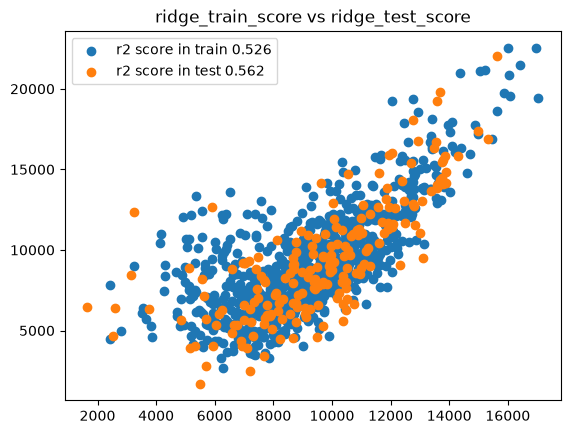

In [65]:
import matplotlib.pyplot as plt
plt.scatter(ridge_train_score,y_train,label=(f"r2 score in train {r2_ridge_train_score:0.3f}"))
plt.scatter(ridge_test_score,y_test,label=(f'r2 score in test {r2_ridge_test_score:0.3f}'))
plt.legend();plt.title('ridge_train_score vs ridge_test_score')

LASSO 


In [68]:
from sklearn.linear_model import Lasso

Lasso_model=Lasso(alpha=0.1)
Lasso_model.fit(x_train_final,y_train)

Lasso_model_train_score=Lasso_model.predict(x_train_final)
Lasso_model_test_score=Lasso_model.predict(x_test_final)

r2_Lasso_model_train_score=r2_score(y_train,Lasso_model_train_score)
r2_Lasso_model_test_score=r2_score(y_test,Lasso_model_test_score)

Text(0.5, 1.0, 'lasso_train_score vs lasso_test_score')

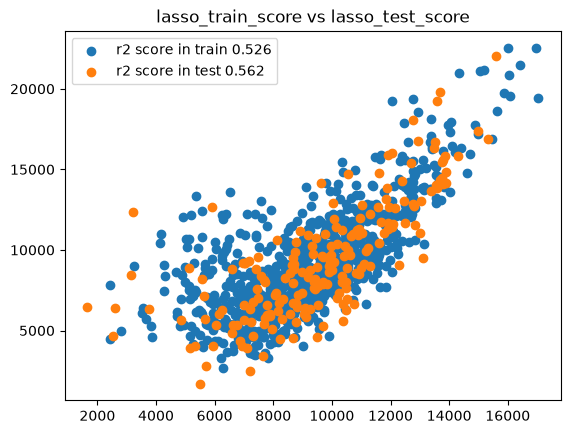

In [69]:
import matplotlib.pyplot as plt
plt.scatter(Lasso_model_train_score,y_train,label=(f"r2 score in train {r2_Lasso_model_train_score:0.3f}"))
plt.scatter(Lasso_model_test_score,y_test,label=(f'r2 score in test {r2_Lasso_model_test_score:0.3f}'))
plt.legend();plt.title('lasso_train_score vs lasso_test_score')

Elastic net


In [70]:
from sklearn.linear_model import ElasticNet
EN_model=ElasticNet(alpha=0.1,l1_ratio=0.5)

EN_model.fit(x_train_final,y_train)

EN_model_train_score=EN_model.predict(x_train_final)
EN_model_test_score=EN_model.predict(x_test_final)

r2_EN_model_train_score=r2_score(y_train,EN_model_train_score)
r2_EN_model_test_score=r2_score(y_test,EN_model_test_score)

Text(0.5, 1.0, 'ELASTICNET_train_score vs ELASTICNET_test_score')

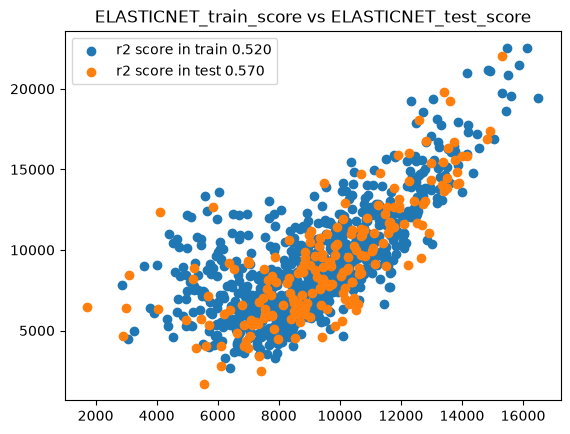

In [71]:
import matplotlib.pyplot as plt
plt.scatter(EN_model_train_score,y_train,label=(f"r2 score in train {r2_EN_model_train_score:0.3f}"))
plt.scatter(EN_model_test_score,y_test,label=(f'r2 score in test {r2_EN_model_test_score:0.3f}'))
plt.legend();plt.title('ELASTICNET_train_score vs ELASTICNET_test_score')

POLY+RIDGE REGRESSION


In [77]:
ridge_model.fit(x_train_poly,y_train)

ridge_poly_train_score=ridge_model.predict(x_train_poly)
ridge_poly_test_score=ridge_model.predict(x_test_poly)

ri_po_r2_train_score=r2_score(y_train,ridge_poly_train_score)
ri_po_r2_test_score=r2_score(y_test,ridge_poly_test_score)

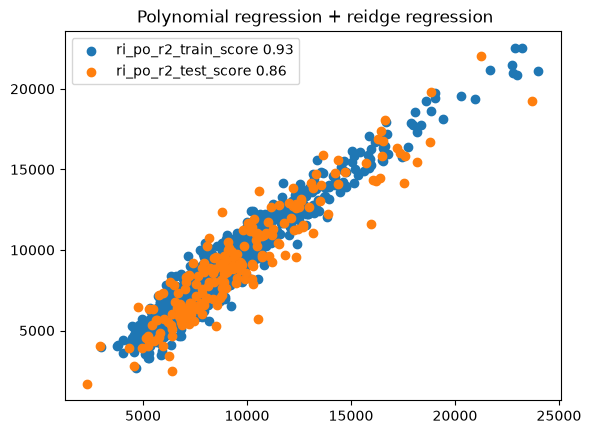

In [81]:
import matplotlib.pyplot as plt
plt.scatter(ridge_poly_train_score,y_train,label=(f"ri_po_r2_train_score {ri_po_r2_train_score:0.2f}"))
plt.scatter(ridge_poly_test_score,y_test,label=(f"ri_po_r2_test_score {ri_po_r2_test_score:0.2f}"))
plt.title(" Polynomial regression + reidge regression");plt.legend()

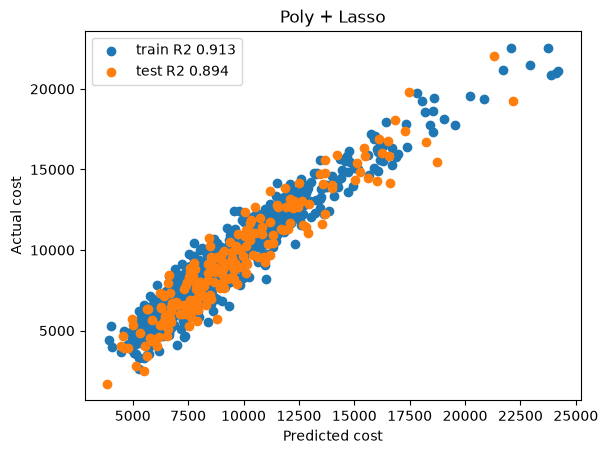

In [83]:
from sklearn.linear_model import Lasso

model = Lasso(alpha=30)
model.fit(x_train_poly, y_train)

pred_train = model.predict(x_train_poly)
pred_test = model.predict(x_test_poly)

r2_train = r2_score(y_train, pred_train)
r2_test = r2_score(y_test, pred_test)


plt.scatter(pred_train, y_train, label=f'train R2 {r2_train:.3f}')
plt.scatter(pred_test, y_test, label=f'test R2 {r2_test:.3f}')
plt.xlabel('Predicted cost')
plt.ylabel('Actual cost')
plt.title('Poly + Lasso')
plt.legend()
plt.show()

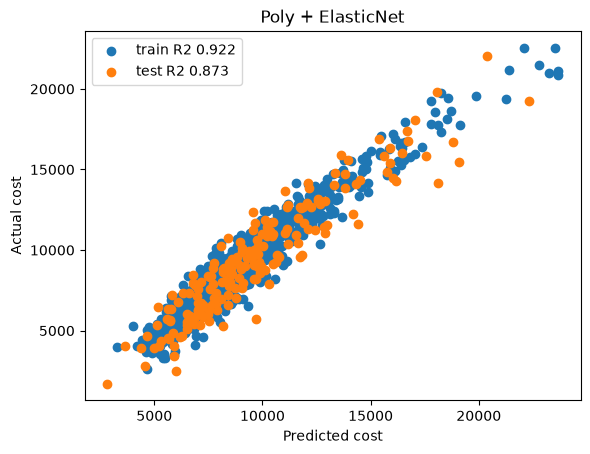

In [84]:
from sklearn.linear_model import ElasticNet

model = ElasticNet(alpha=0.1, l1_ratio=0.5)
model.fit(x_train_poly, y_train)

pred_train = model.predict(x_train_poly)
pred_test = model.predict(x_test_poly)

r2_train = r2_score(y_train, pred_train)
r2_test = r2_score(y_test, pred_test)


plt.scatter(pred_train, y_train, label=f'train R2 {r2_train:.3f}')
plt.scatter(pred_test, y_test, label=f'test R2 {r2_test:.3f}')

plt.xlabel('Predicted cost')
plt.ylabel('Actual cost')
plt.title('Poly + ElasticNet')
plt.legend()
plt.show()